In [ ]:
# author: Stutie Banerjie
# date: 11.12.2026
# desc: EDA for Data Center Dataset for DTSC 1302 Final Project

### (Preemptive) Research Question
Which socioeconomic characteristics of a census tract (ex. income, poverty, housing costs, education, race, education, etc.) are associated with having a data center? Do the correlations change based on facility size and state?

(Preemptive) Target Variable: 
| Variable | Description | Notes |
| --- | --- | --- |
| has_data_center | Dictates whether or not there is at least one data center in the tract. | 0/1 Flag Variable |

(Preemptive) Predictive Variables
| Variable | Description | Notes |
| --- | --- | --- |
| median_hh_income | Median Household Income in Tract | N/A |
| total_pop | Total Population in Tract | N/A 
| pct_white_nh, pct_black_nh, pct_asian_nh, pct_hispanic, pct_nonwhite | Racial distribution of Tract Population | Would be interesting to see if any, some, or all racial demographies in tract populations had correlation to data centers being build in a specific area. |
| dist_nearest_metro_km | Straight line distance (KM) from tract point to nearest data center | Could potentially show if data centers are built in more rural or urban areas. Might be a grouping variable? |


(Preemptive) Grouping Variables -
| Variable | Description | Options | Notes
| --- | --- | --- | --- |
| states | What state the data was aggregated from. | GA; NC; SC; TN; VA | N/A |
| dc_total_sqft | Total land taken up by data center in city | Range: 1,232 - 26,597,517 | Should probably break these into meaningful categories so building graphs later on is easier.|
| dc_n_campus vs dc_n_building | See what tracts have single building data centers vs multiple buildings for one establishment. | Could be interesting to see if there's a correlation between these categories and different socioeconomic metrics? |


### Set Up

In [46]:
import pandas as pd

df = pd.read_csv("clean.csv")
df.head()

,geoid,state,total_pop,median_hh_income,poverty_rate,pct_white_nh,pct_black_nh,pct_asian_nh,pct_hispanic,pct_nonwhite,...,dist_nearest_dc_km,n_dc_within_10km,nearest_metro,dist_nearest_metro_km,in_charlotte_region,dc_n_campus,dc_n_building,dc_n_point,dc_n_big_tech,dc_n_operator_unknown
0,13001950100,GA,3219,50222.0,19.6,76.7,9.6,0.0,13.5,23.3,...,200.29,0,Charleston SC,242.1,0,0,0,0,0,0
1,13001950201,GA,2246,57653.0,21.5,75.6,15.6,1.0,5.5,24.4,...,207.52,0,Charleston SC,245.1,0,0,0,0,0,0
2,13001950202,GA,2152,29899.0,24.6,41.2,39.9,0.0,15.3,58.8,...,210.28,0,Charleston SC,254.4,0,0,0,0,0,0
3,13001950301,GA,3264,45486.0,25.1,62.3,24.8,0.7,9.4,37.7,...,216.37,0,Charleston SC,253.2,0,0,0,0,0,0
4,13001950302,GA,2144,38673.0,29.7,71.1,14.2,1.4,7.1,28.9,...,215.21,0,Charleston SC,258.4,0,0,0,0,0,0


### Data Exploration
Step 1: Summary Statistics

In [55]:
# summary statistics - area & population metrics

df[['land_sqmi', 
    'total_pop', 
    'pop_density_sqmi']].describe().round(2)

,land_sqmi,total_pop,pop_density_sqmi
count,10599.00,10599.00,10599.00
mean,20.36,4032.32,1978.01
std,36.41,1777.05,3436.77
min,0.03,2.00,0.00
25%,1.42,2778.00,164.95
50%,4.24,3795.00,1007.40
75%,22.32,4984.00,2658.25
max,515.98,18754.00,103384.60


In [56]:
# summary statistics - race distribution
df[['pct_white_nh', 
    'pct_black_nh', 
    'pct_asian_nh', 
    'pct_hispanic']].describe().round(2)

,pct_white_nh,pct_black_nh,pct_asian_nh,pct_hispanic
count,10599.00,10599.00,10599.00,10599.00
mean,58.87,23.22,3.51,9.54
std,26.25,23.70,6.47,10.41
min,0.00,0.00,0.00,0.00
25%,40.00,4.60,0.00,2.80
50%,63.80,15.00,1.10,6.40
75%,80.80,34.40,3.80,12.30
max,100.00,100.00,67.90,98.90


In [57]:
# summary statistics - socioeconomic metrics (dollar variables)
df[['median_hh_income', 
    'median_gross_rent', 
    'median_home_value']].describe().round(2)

# note: max values are caps

,median_hh_income,median_gross_rent,median_home_value
count,10525.00,10053.00,10370.00
mean,81665.27,1348.65,323293.74
std,40740.61,573.27,207549.26
min,2499.00,99.00,13500.00
25%,54272.00,913.00,186300.00
50%,71471.00,1207.00,271600.00
75%,97705.00,1687.00,398700.00
max,250001.00,3501.00,2000001.00


In [59]:
# summary statistics - socioeconomic metrics (percentage variables)
df[['poverty_rate',
    'pct_bachelors_plus',
    'unemployment_rate',
    'pct_owner_occupied',
    'pct_no_vehicle',
    'pct_rent_burdened']].describe().round(2)

,poverty_rate,pct_bachelors_plus,unemployment_rate,pct_owner_occupied,pct_no_vehicle,pct_rent_burdened
count,10567.00,10598.00,10577.00,10562.00,10562.00,10549.00
mean,13.92,34.23,5.04,67.03,6.11,41.92
std,10.93,20.55,4.40,22.47,7.09,19.03
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,6.00,18.00,2.10,53.50,1.60,29.40
50%,11.30,29.00,3.90,72.90,3.90,42.40
75%,19.00,47.00,6.70,84.40,8.10,54.80
max,100.00,100.00,52.80,100.00,100.00,100.00


In [62]:
# summary statistics - data center size & location metrics
df[['n_data_centers',
    'dc_total_sqft',
    'dist_nearest_dc_km',
    'n_dc_within_10km',
    'dist_nearest_metro_km']].describe().round(2)

,n_data_centers,dc_total_sqft,dist_nearest_dc_km,n_dc_within_10km,dist_nearest_metro_km
count,10599.00,10599.00,10599.00,10599.00,10599.00
mean,0.04,17923.87,63.38,1.82,75.30
std,0.81,448187.96,62.96,13.13,63.69
min,0.00,0.00,0.05,0.00,0.20
25%,0.00,0.00,13.92,0.00,23.90
50%,0.00,0.00,45.15,0.00,55.50
75%,0.00,0.00,92.72,0.00,117.75
max,60.00,27106734.00,337.84,202.00,359.40


In [63]:
# summary statistics - data center sprawl
df[['dc_n_campus',
    'dc_n_building',
    'dc_n_point',
    'dc_n_operator_unknown']].describe().round(2)

,dc_n_campus,dc_n_building,dc_n_point,dc_n_operator_unknown
count,10599.0,10599.00,10599.00,10599.00
mean,0.0,0.03,0.00,0.01
std,0.1,0.74,0.04,0.21
min,0.0,0.00,0.00,0.00
25%,0.0,0.00,0.00,0.00
50%,0.0,0.00,0.00,0.00
75%,0.0,0.00,0.00,0.00
max,6.0,54.00,2.00,15.00


Step 2: Visualizations & Identified Patterns

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

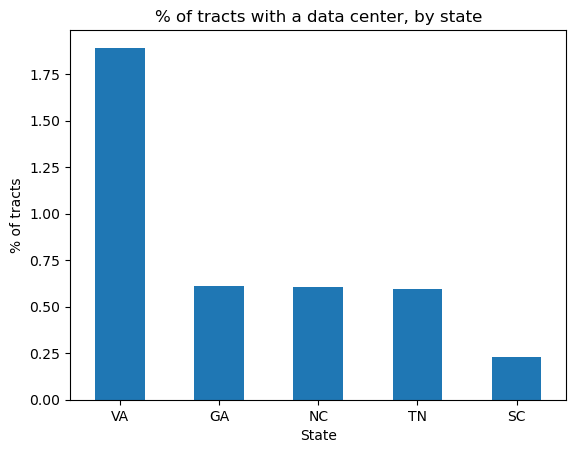

In [66]:
# question: Which states have data centers?
state_rate = df.groupby('state')['has_data_center'].mean() * 100
state_rate = state_rate.sort_values(ascending=False)

state_rate.plot(kind='bar')
plt.title('% of tracts with a data center, by state')
plt.xlabel('State')
plt.ylabel('% of tracts')
plt.xticks(rotation=0)
plt.show()

<u>What it does:</u> For each state, it shows the share of census tracts that contain at least one data center. Using a percentage, not a raw count, keeps states with more tracts from looking bigger just because of size.

<u>Why it’s relevant:</u> Shows the distribution of data centers by state. This tells us whether data centers are spread evenly across the five states or concentrated in one.

<u> Pattern: </u> Virginia is far ahead at about 1.9% of tracts. Georgia, North Carolina and Tennessee are close together at roughly 0.6%, and South Carolina is lowest at about 0.2%. Most of the 87 data center tracts are in Virginia (41), so state is likely to matter in a model.

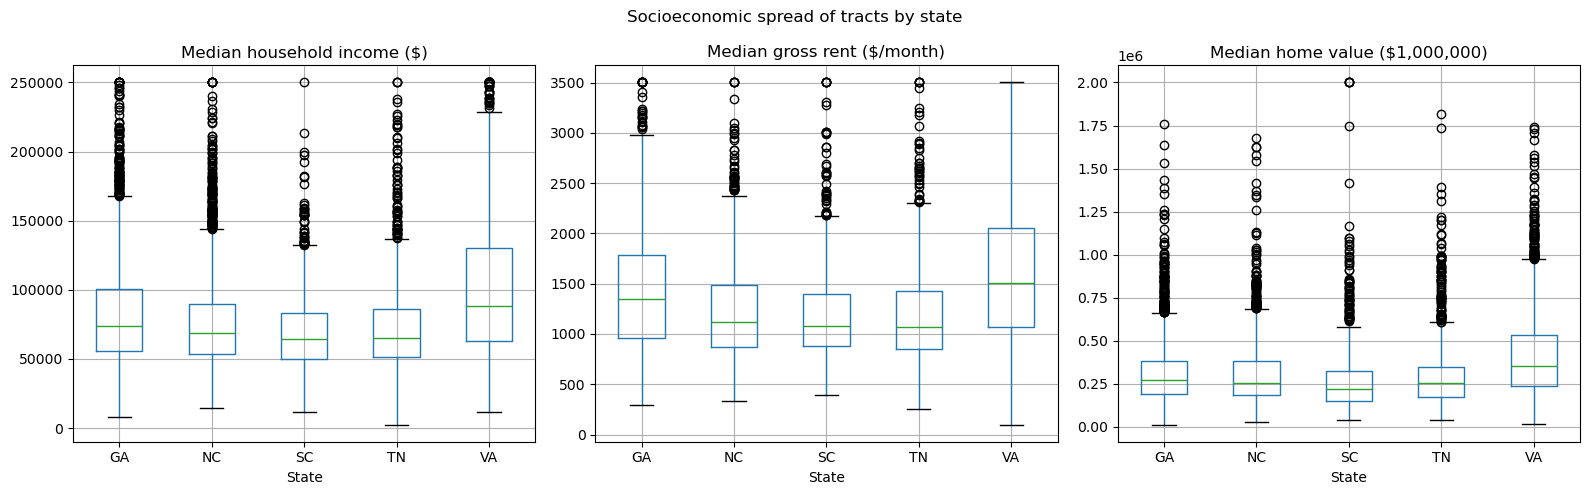

In [ ]:
# question: How does socioeconomic status ($) vary by state?

cols = ['median_hh_income', 'median_gross_rent', 'median_home_value']
titles = ['Median household income ($)', 'Median gross rent ($/month)', 'Median home value ($1,000,000)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, title in zip(axes, cols, titles):
    df.boxplot(column=col, by='state', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('State')
    ax.set_ylabel('')

plt.suptitle('Socioeconomic spread ($) of tracts by state')
plt.tight_layout()
plt.show()

<u>What it does:</u> Highlights the spread of median household income, rent and home value across tracts, aggregated by state. The green line in each box is the median tract, the box covers the middle 50% of tracts, and the dots are outlier values.

<u>Why it’s relevant:</u> Before comparing data center counts, socioeconomic metrics, and state, it's important to understand the baseline wealth of each state. Moving foward, we can note if "high income" means differently in tracts based on which state they're in.

<u> Pattern: </u> Virginia’s typical tract is higher on all three: median income around $88,000, against roughly $65,000–$75,000 elsewhere, with higher rent and home values too. Virginia’s boxes are also taller, so its tracts vary more. 

<u> Note: </u> The flat rows of dots at the top of income ($250,001) and rent ($3,501) are the cap values from the data dictionary, not real values.

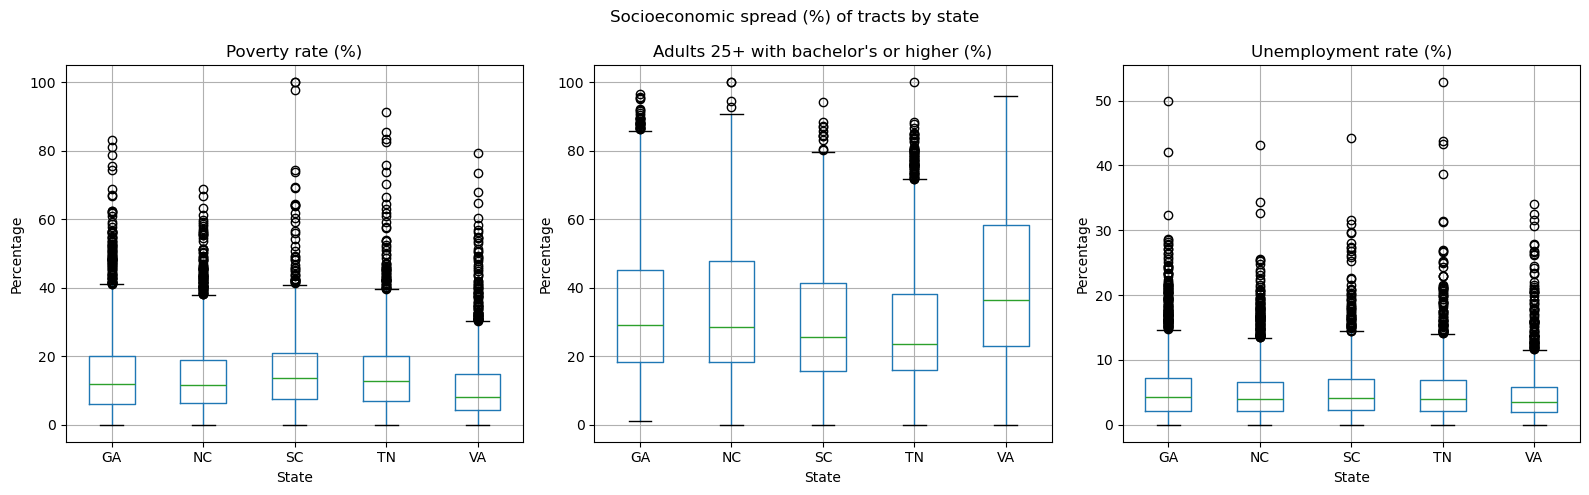

In [73]:
# question: How does socioeconomic status (%) vary by state?

cols = ['poverty_rate', 'pct_bachelors_plus', 'unemployment_rate']
titles = ['Poverty rate (%)', 'Adults 25+ with bachelor\'s or higher (%)', 'Unemployment rate (%)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, title in zip(axes, cols, titles):
    df.boxplot(column=col, by='state', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('State')
    ax.set_ylabel('Percentage')

plt.suptitle('Socioeconomic spread (%) of tracts by state')
plt.tight_layout()
plt.show()

<u> What it does: </u> Same comparison as above, but for poverty rate, education rates, and unemployment rates. 

<u> Why it's relevant: </u> Shows another relationship between socioeconomic metrics by state, which may be relevant predictors in our logistic regression model later on in our project process.

<u> Pattern: </u> Virginia again stands out, with the highest typical education level (median around 36% with a bachelor’s or higher, against 23–29% elsewhere) and the lowest poverty and unemployment. Unemployment looks similar across states, with a few extreme outliers (up to about 53%) that are probably small or unusual tracts and not errors.

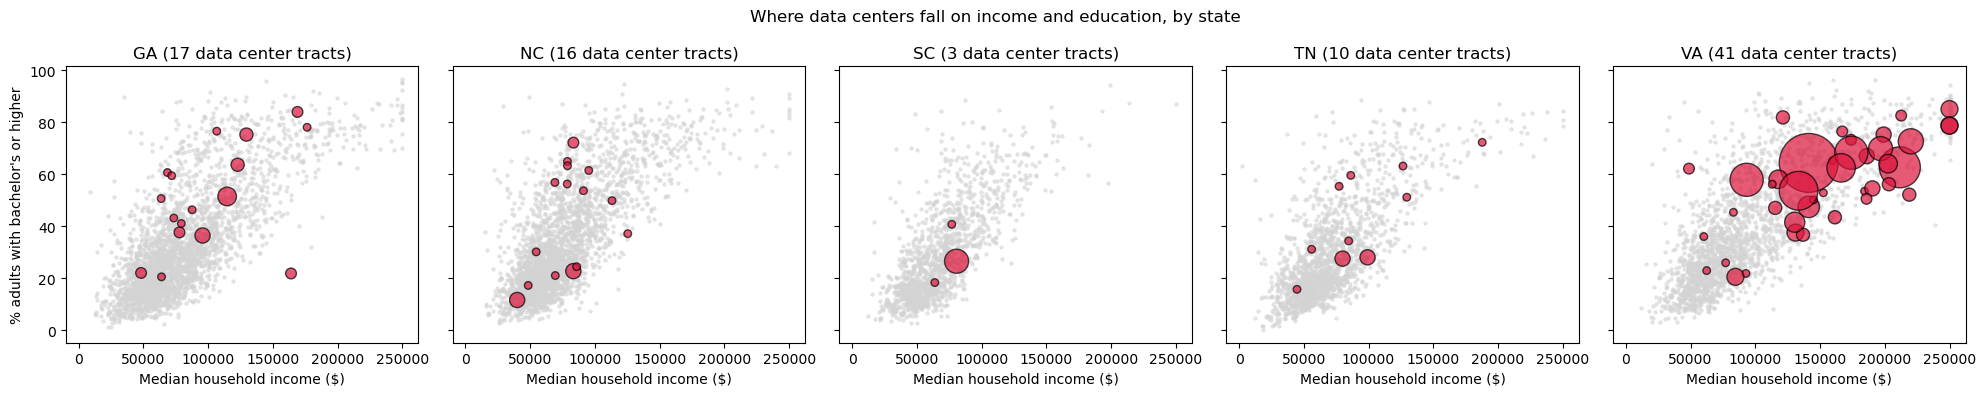

In [ ]:
# question: where do data centers fall on income and education, by state?

states = sorted(df['state'].unique())

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

for ax, st in zip(axes, states):
    state_df = df[df['state'] == st]
    no_dc = state_df[state_df['has_data_center'] == 0]
    dc = state_df[state_df['has_data_center'] == 1]

    # background: all tracts without a data center
    ax.scatter(no_dc['median_hh_income'], no_dc['pct_bachelors_plus'],
               s=5, color='lightgray', alpha=0.5)

    # foreground: data center tracts, sized by number of data centers
    ax.scatter(dc['median_hh_income'], dc['pct_bachelors_plus'],
               s=dc['n_data_centers'] * 30, color='crimson', alpha=0.7,
               edgecolor='black')

    ax.set_title(f"{st} ({len(dc)} data center tracts)")
    ax.set_xlabel('Median household income ($)')

axes[0].set_ylabel("% adults with bachelor's or higher")
plt.suptitle('Where data centers fall on income and education, by state')
plt.tight_layout()
plt.show()

<u> What it does: </u> Each panel is one state. Gray dots are tracts without a data center, and red dots are tracts with one, sized by how many data centers they have. All panels share the same axes.

<u> Why it’s relevant: </u> This is the closest chart to our main question. It shows where data center tracts sit compared with typical tracts, and whether that differs by state.

<u> Pattern: </u> Income and education rise together across all tracts (the gray cloud slopes upward). In Virginia, the red dots cluster in the upper right, with higher incomes and higher education, and the largest dots are there too. In Georgia, North Carolina and Tennessee the red dots are more spread out, with several in the middle of the gray cloud, so the pattern is weaker. South Carolina has only three data center tracts, which is too few to say anything.

Note: Claude Assisted Code

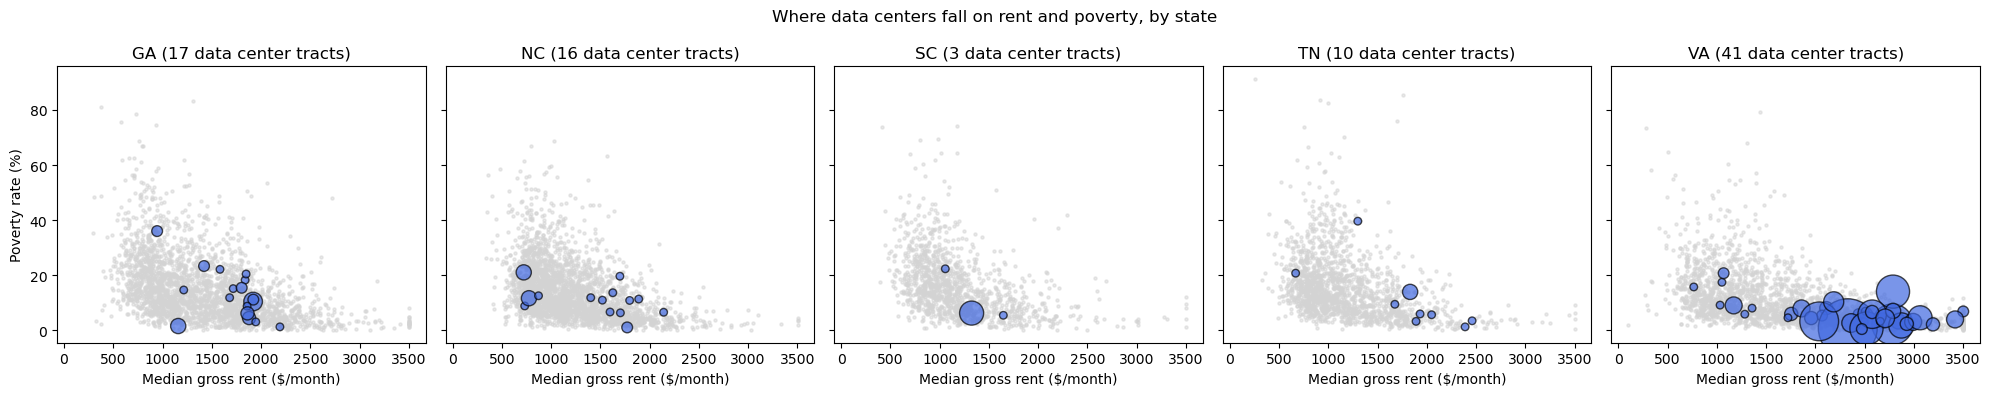

In [79]:
# question: where do data centers fall on rent and poverty, by state?

states = sorted(df['state'].unique())

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

for ax, st in zip(axes, states):
    state_df = df[df['state'] == st]
    no_dc = state_df[state_df['has_data_center'] == 0]
    dc = state_df[state_df['has_data_center'] == 1]

    # background: all tracts without a data center
    ax.scatter(no_dc['median_gross_rent'], no_dc['poverty_rate'],
            s=5, color='lightgray', alpha=0.5)

    # foreground: data center tracts, sized by number of data centers
    ax.scatter(dc['median_gross_rent'], dc['poverty_rate'],
               s=dc['n_data_centers'] * 30, color='royalblue', alpha=0.7,
                edgecolor='black')

    ax.set_title(f"{st} ({len(dc)} data center tracts)")
    ax.set_xlabel('Median gross rent ($/month)')

axes[0].set_ylabel('Poverty rate (%)')
plt.suptitle('Where data centers fall on rent and poverty, by state')
plt.tight_layout()
plt.show()


What it does: The same layout as chart 4, with rent on the x-axis and poverty rate on the y-axis.

Why it’s relevant: It looks at housing cost and economic hardship, a different angle from income and education.

Pattern: Across all tracts, higher rent goes with lower poverty. Most data center tracts sit in the lower right, with higher rent and low poverty (mostly under about 15–20%). That’s clearest in Virginia, where many large dots sit at rents of $2,000–$3,500. In the other states the dots are more mixed, with some in average-rent, average-poverty tracts. Tracts missing a rent value don’t appear on this chart.

Note: Claude Assisted Code

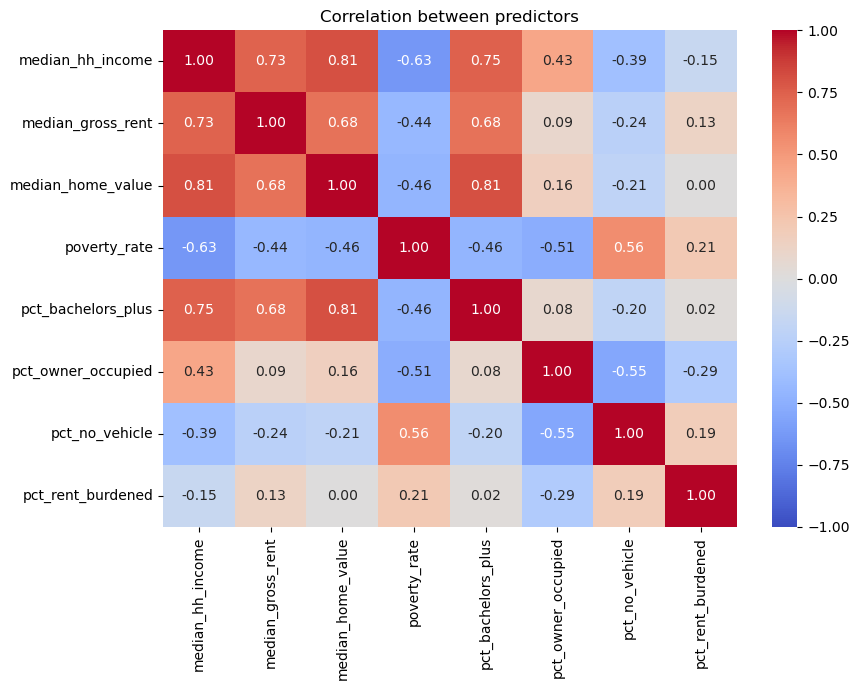

In [88]:
# correlation between socioeconomic predictors
predictors = ['median_hh_income', 'median_gross_rent', 'median_home_value',
              'poverty_rate', 'pct_bachelors_plus', 'pct_owner_occupied',
              'pct_no_vehicle', 'pct_rent_burdened']

plt.figure(figsize=(9, 7))
sns.heatmap(df[predictors].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between predictors')
plt.tight_layout()
plt.show()

What it does: Each cell shows how strongly two variables move together, from −1 to +1. Dark red means they rise together, and dark blue means one rises as the other falls.

Why it’s relevant: Since our end goal is to fit a model, we decided to look into our predictor correlations. The intended purpose of this chart is to see which variables are strongly correlated with each other, and in turn carry overlapping information and make it harder to tell their effects apart.

Pattern: Income, home value, bachelor’s degree and rent are strongly related to each other (correlations of about 0.68–0.81), so they’re measuring something similar, roughly overall affluence. Poverty is moderately negatively related to income (−0.63). pct_owner_occupied and pct_rent_burdened are only weakly related to most others, so they may add separate information. When choosing predictors for the model, we will probably be able to choose 2-3 of these, and some other variables of choice.

Note: Claude Assisted Code

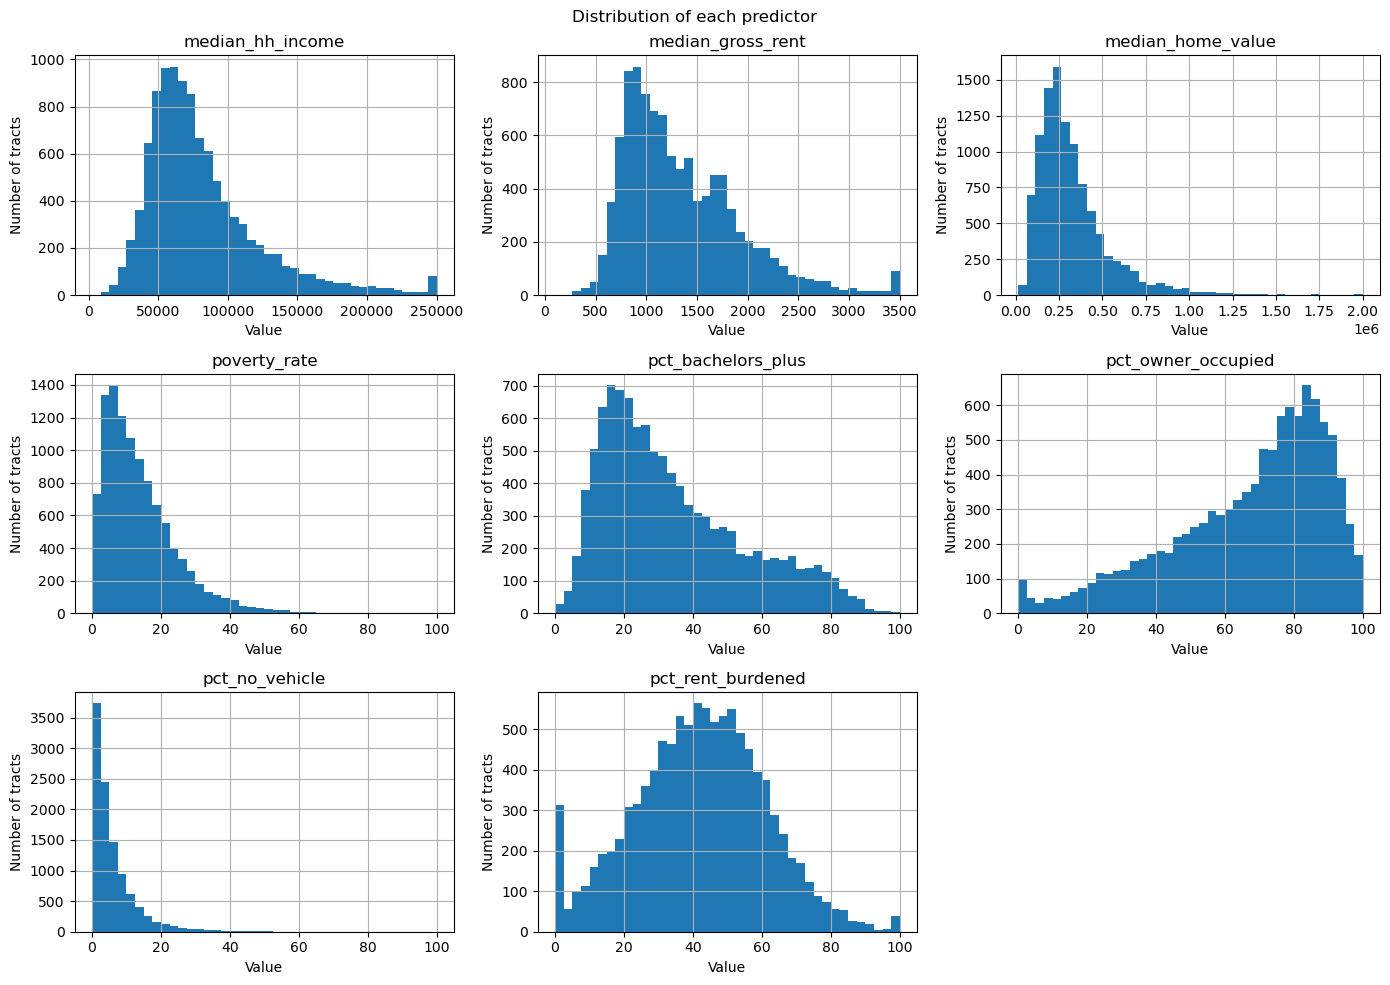

In [87]:
# shape of predictors

axes = df[predictors].hist(bins=40, figsize=(14, 10), layout=(3, 3))

for ax in axes.flatten():
    ax.set_xlabel('Value')
    ax.set_ylabel('Number of tracts')

plt.suptitle('Distribution of each predictor')
plt.tight_layout()
plt.show()

What it does: It shows how the tracts are spread across the values of each variable. The x-axis is the value and the y-axis is the number of tracts.

Why it’s relevant: The shape of a variable affects how we can use the variable in a model and shows any interesting data quirks ahead of time.

Pattern: Income, rent, home value, poverty and no-vehicle are right-skewed, with most tracts at lower values and a long tail of high ones. Owner-occupied is skewed the other way, with most tracts at 70–90%. Rent burden is roughly bell-shaped. Income and rent have small spikes at the right edge from the cap values. Rent burden and owner-occupied have spikes at 0 and 100, probably from very small tracts.